In [30]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,)

In [40]:
CSV_PATH = "outputs/deepdetect_edge_features.csv"
df = pd.read_csv(CSV_PATH)
print("Dataset shape:", df.shape)
display(df.sample(5))

Dataset shape: (200, 10)


,sobel_mean,sobel_std,laplacian_mean,laplacian_variance,canny_edge_density,noise_mean,noise_std,filename,image_type,label
187,9.084004,31.843329,4.795221,414.024053,0.035694,2.601204,8.567847,stego_088.png,stego,1
46,8.835858,33.339910,4.852320,508.556993,0.030572,2.266960,8.078758,clean_047.png,clean,0
148,10.943060,40.105193,4.843172,407.145905,0.032864,2.460858,8.146656,stego_049.png,stego,1
1,10.502551,32.853892,5.990095,513.416256,0.047533,2.982920,8.745886,clean_002.png,clean,0
105,7.159997,24.616958,4.627611,349.869597,0.048788,2.413504,8.009795,stego_006.png,stego,1


In [31]:
print("Column names are")
print(df.columns.tolist())

Column names are
['sobel_mean', 'sobel_std', 'laplacian_mean', 'laplacian_variance', 'canny_edge_density', 'noise_mean', 'noise_std', 'filename', 'image_type', 'label']


In [32]:
feature_columns = [
    "sobel_mean",
    "sobel_std",
    "laplacian_mean",
    "laplacian_variance",
    "canny_edge_density",
    "noise_mean",
    "noise_std"
]

In [33]:
X = df[feature_columns]
y = df["label"]
print("Input feature shape is", X.shape)
print("Target shape is", y.shape)

Input feature shape is (200, 7)
Target shape is (200,)


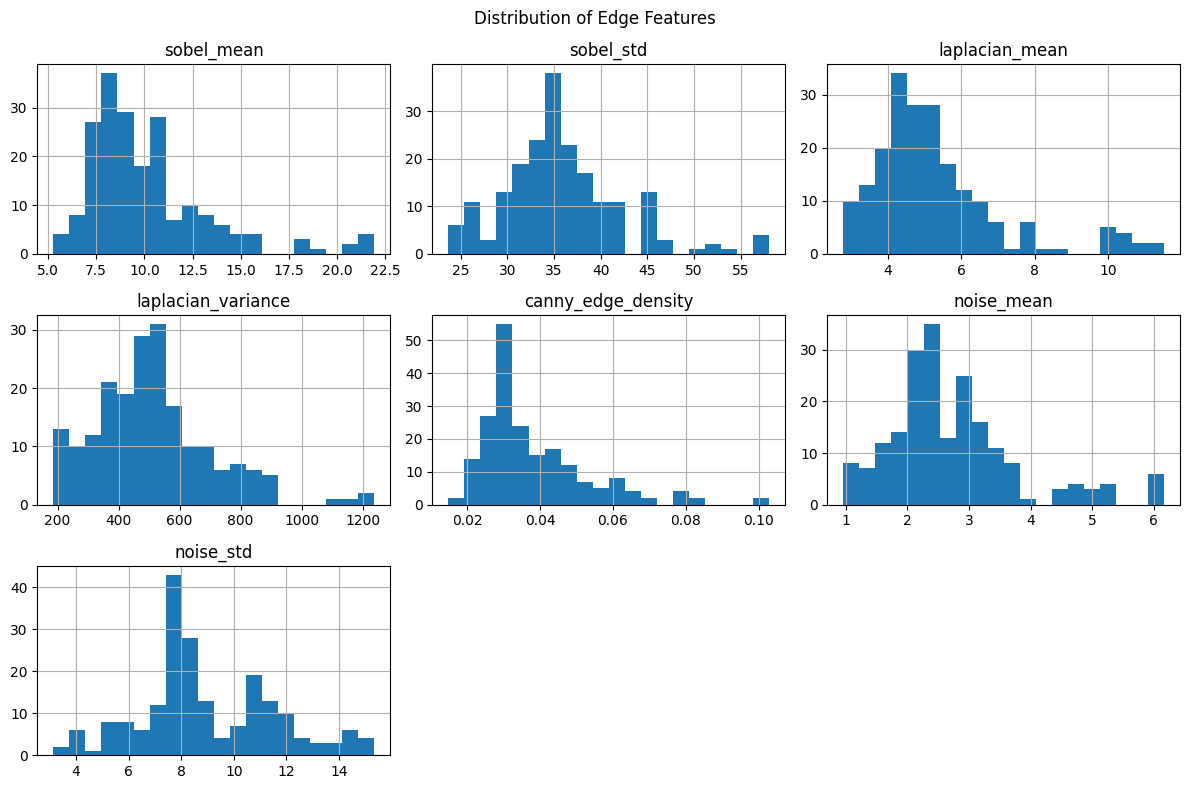

In [17]:
X.hist(figsize=(12, 8),bins=20)
plt.suptitle("Distribution of Edge Features")
plt.tight_layout()
plt.show()

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [34]:
print("number of training samples are", len(X_train))
print("number of testing samples are", len(X_test))

number of training samples are 160
number of testing samples are 40


In [35]:
logistic_model = Pipeline([("scaler", StandardScaler()),("classifier",LogisticRegression(max_iter=1000))])

In [36]:
logistic_model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [37]:
y_pred = logistic_model.predict(X_test)
print("First 10 actual labels are", y_test.to_numpy()[:10])
print("First 10 predicted labels are", y_pred[:10])

First 10 actual labels are [0 1 1 1 0 1 0 1 1 0]
First 10 predicted labels are [1 1 1 1 0 0 0 1 1 0]


In [29]:
precision = precision_score(y_test,y_pred,zero_division=0)
recall = recall_score(y_test,y_pred,zero_division=0)
f1 = f1_score(y_test,y_pred,zero_division=0)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

Precision: 0.6087
Recall: 0.7
F1-score: 0.6512
